# 01 · Validación del simulador HANDY
Reproducimos cualitativamente los escenarios canónicos de Motesharrei et al. (2014) antes de extender el modelo. Las ecuaciones están en `src/worldsim/simulator/handy.py` y las decisiones en `docs/DECISIONES.md`.

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.4f}".format

,collapsed,t_collapse,pop_final,nature_final
Igualitario: aterrizaje suave (1x δ*),False,1000.0000,74999.9813,49.9750
Igualitario: oscilaciones (2.5x),False,1000.0000,47982.0151,19.9900
Igualitario: ciclos de colapso (4x),True,418.0000,68915.8954,0.0000
"Igualitario: Tipo-N irreversible (12x, RK4)",True,397.0000,0.0000,0.0000
"Igualitario: Tipo-N irreversible (5.5x, Euler float32)",True,420.0000,0.0000,0.0000
"Equitativo (κ=1, x_E(0)=25)",False,1000.0000,70335.2683,62.4691
"Desigual: Tipo-L (κ=100, x_E(0)=1e-3)",True,740.0000,0.0000,100.0000
"Desigual: Tipo-N (κ=100, δ=1e-4)",True,386.0000,0.0000,0.0000


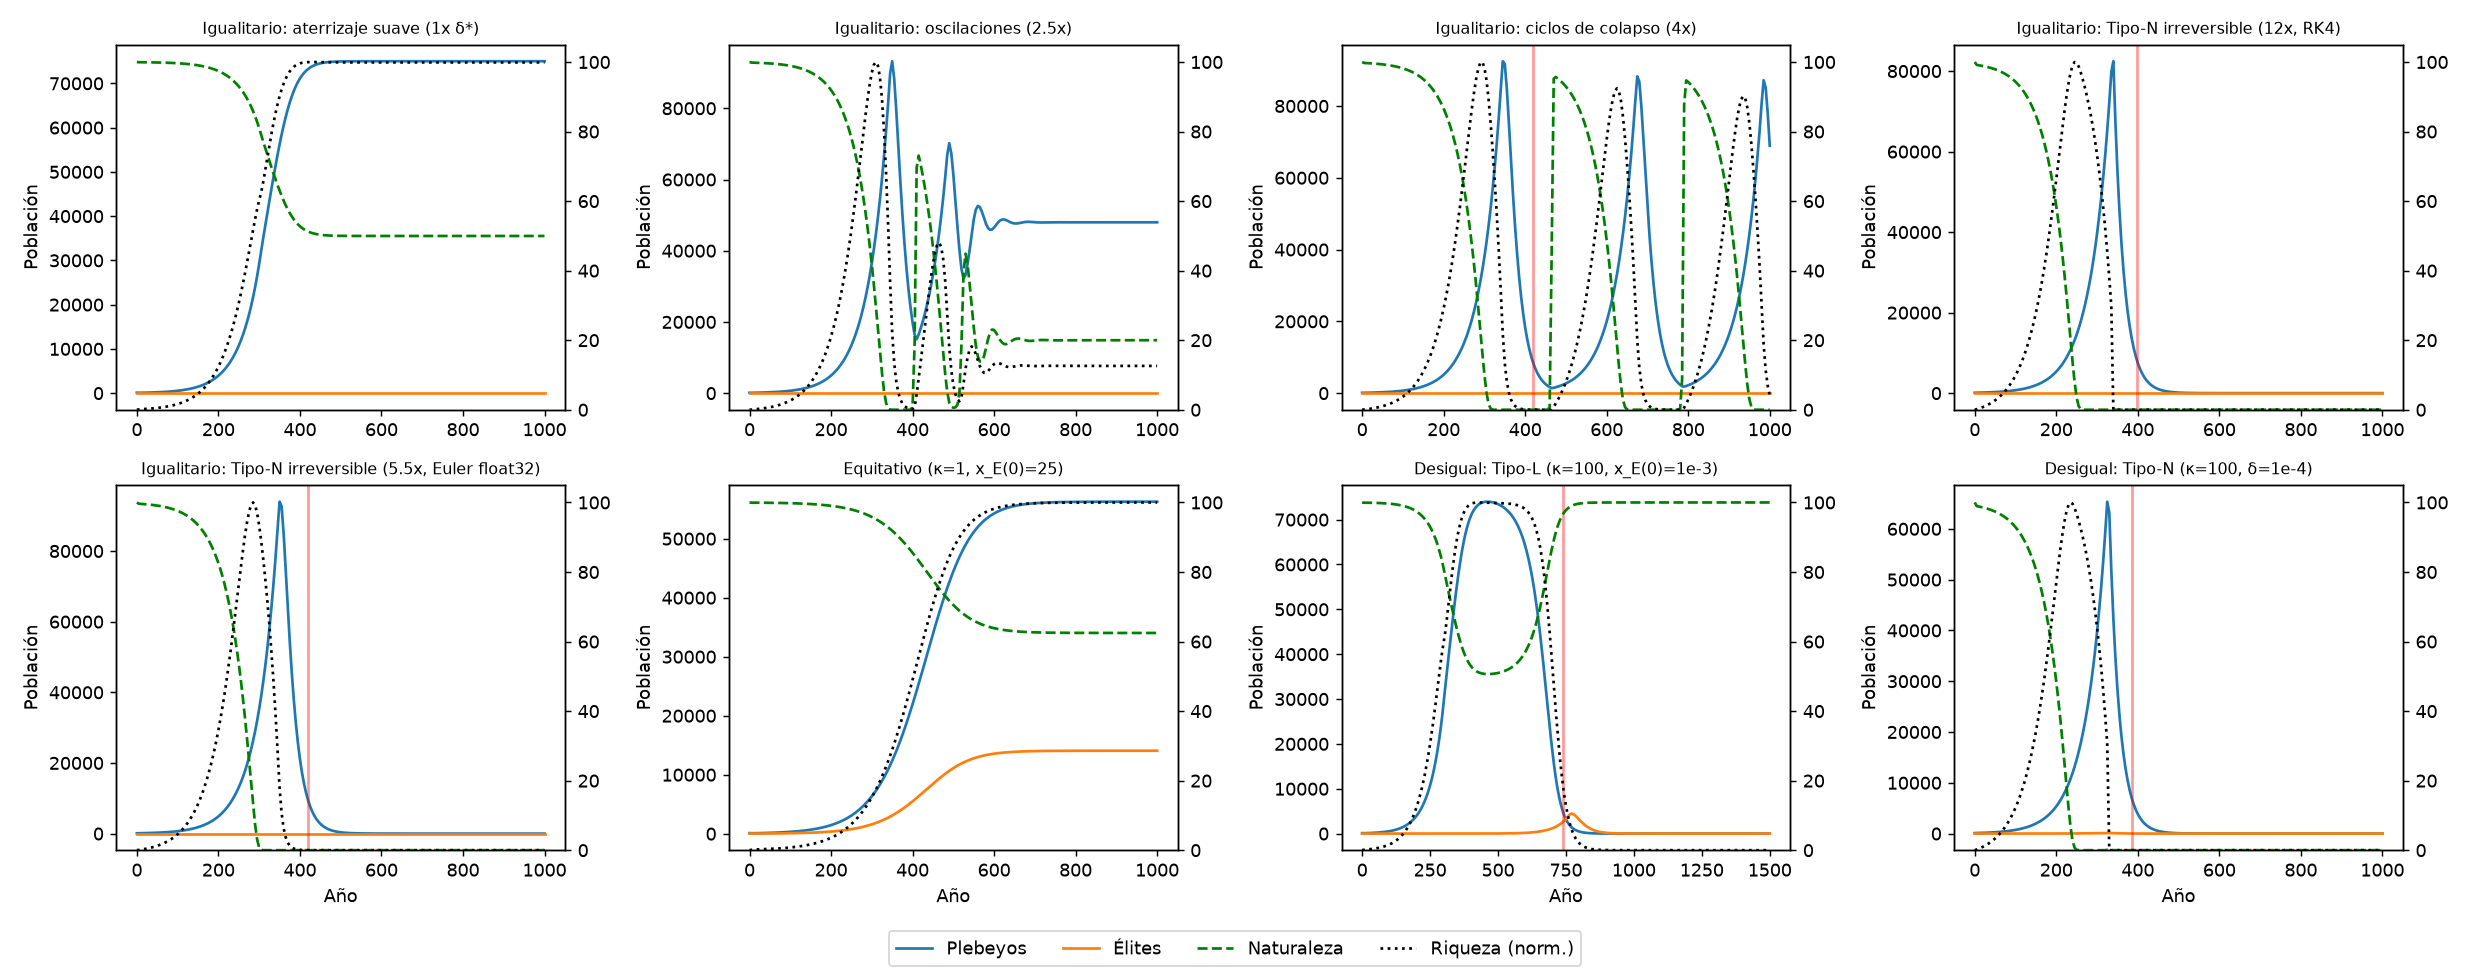

In [2]:
from pathlib import Path
from worldsim.simulator.scenarios import plot_scenarios
summary = plot_scenarios(Path('report/figures/fig_escenarios_handy.png'))
display(pd.DataFrame(summary).T)
display(Image('report/figures/fig_escenarios_handy.png'))

**Lectura.** Se reproducen el equilibrio, las oscilaciones, los ciclos de colapso, el colapso Tipo-L (la población muere, la naturaleza se recupera) y el Tipo-N con κ=100. El umbral del Tipo-N *igualitario* depende del integrador: RK4 desde ≈9.25×δ*, Euler (dt=1, float32, como el paper) desde ≈3.25×δ*; el paper reporta 4× reversible y 5.5× irreversible, entre ambos (ver D-03).

In [3]:
import subprocess
print(subprocess.run([sys.executable, '-m', 'pytest', '-q'], capture_output=True, text=True).stdout[-300:])

...............                                                          [100%]
15 passed in 3.04s

